# XAUUSD bull/bear v0.2 — holdout backtest ส.ค.–ก.ย. 2026

ช่วงนี้ถูกกันไว้ตั้งแต่ต้น (`config.FORBIDDEN_FROM`) — notebook เทรนไม่เคยโหลด ใช้โมเดลที่ save ไว้ใน `models/v2/` **ตามที่ save มาเป๊ะๆ** (τ/m/calibrator ไม่จูนใหม่) แล้วรันครั้งเดียว

- ข้อมูล: CSV ของ broker จบ 2026-01-30 จึงใช้ feed เดียวกับ harness backtest คือ `GC=F` (yfinance) แปลงเป็นเวลา server ของ broker (NY+7h), 1d resample จาก 1h
- label/simulator: triple-barrier เดิม (SL 1R, TP 1.5R / 2.5R ถ้าสวนเทรนด์รายวัน, time stop ตาม horizon, stop_first, ค่าใช้จ่าย $0.30/oz) ถือได้ทีละ position
- baseline บนแถวเดียวกัน: always long, always short, SMA20/50 cross

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from xau_ml import holdout as H, data as D
from xau_ml.cv import bootstrap_mean_ci, bootstrap_diff_ci
from xau_ml.config import MODEL_DIR_V2
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
bars = H.load_bars()
{tf: (b["date"].min(), b["date"].max(), len(b)) for tf, b in bars.items()}

{'15m': (Timestamp('2026-07-27 01:00:00'),
  Timestamp('2026-10-02 23:45:00'),
  4487),
 '1h': (Timestamp('2025-01-02 07:00:00'),
  Timestamp('2026-10-02 23:00:00'),
  10063),
 '1d': (Timestamp('2025-01-02 00:00:00'),
  Timestamp('2026-10-02 00:00:00'),
  450)}

## ตรวจการแปลงเวลา — เทียบ GC=F กับ CSV ของ broker ช่วงที่ทับกัน (2025-01..2026-01)

In [2]:
b1 = D.load("1h", start="2025-01-01")
r1 = b1.set_index("date")["close"].pipe(np.log).diff()
r2 = bars["1h"].set_index("date")["close"].pipe(np.log).diff()
pd.Series({lag: pd.concat([r1, r2.shift(lag, freq="h")], axis=1, join="inner").dropna().corr().iloc[0, 1]
           for lag in (-2, -1, 0, 1, 2)}, name="corr of 1h returns vs clock shift (h)").round(3)

-2   -0.018
-1    0.038
0     0.721
1    -0.014
2    -0.031
Name: corr of 1h returns vs clock shift (h), dtype: float64

In [3]:
# gap ใหญ่สุดในช่วง holdout (ถ้ามี contract roll จะโผล่ตรงนี้) — ทั้งหมดเป็นเปิดตลาดวันจันทร์
H.gap_report(bars["15m"], "15m").round(2)

,date,open,gap_atr
0,2026-09-14 01:00:00,4371.9,4.00
1,2026-08-03 01:00:00,4131.1,3.74
2,2026-09-28 01:00:00,4308.8,1.78
3,2026-08-31 01:00:00,4506.3,1.60
4,2026-09-21 01:00:00,4415.0,1.34


## Intraday (15m) — `xau_intraday_ct25`

In [4]:
pred_i, fr_i = H.frame(MODEL_DIR_V2 / "xau_intraday_ct25.json", bars)
res_i = H.backtest(fr_i)
print(pred_i.meta["signal_rule"]["rule"], "| tau", pred_i.meta["signal_rule"]["tau"])
H.summary(res_i).round(3)

long if p_bull>=tau and p_bull-p_bear>=m; short mirrored; else flat | tau 0.375


,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,long_share,longs,shorts,return_pct
strategy,,,,,,,,,,
model,90,0.478,1.313,0.162,14.606,7.868,1.0,90,0,14.880
always_long,476,0.405,0.947,-0.030,-14.085,37.462,1.0,476,0,-15.964
always_short,484,0.413,0.930,-0.040,-19.157,37.470,0.0,0,484,-20.101
sma_cross,76,0.434,1.081,0.045,3.419,9.317,0.5,38,38,2.884


In [5]:
H.by_month(res_i["model"])

,trades,win_rate,profit_factor,expectancy_r,total_r,longs,shorts
2026-08,8.0,0.50000,1.139121,0.071611,0.572889,8.0,0.0
2026-09,82.0,0.47561,1.329949,0.171140,14.033498,82.0,0.0


In [6]:
m, al = res_i["model"]["r"].to_numpy(), res_i["always_long"]["r"].to_numpy()
print("expectancy 90% CI:", np.round(bootstrap_mean_ci(m), 3))
print("model - always_long 90% CI:", np.round(bootstrap_diff_ci(m, al), 3))

expectancy 90% CI: [-0.055  0.39 ]
model - always_long 90% CI: [-0.042  0.433]


## Swing (1h) — `xau_swing_ct25`

In [7]:
pred_s, fr_s = H.frame(MODEL_DIR_V2 / "xau_swing_ct25.json", bars)
res_s = H.backtest(fr_s)
pos = H.holdout_rows(fr_s)
print("long signals", int((fr_s["signal"].to_numpy()[pos] == 1).sum()), "of", len(pos), "rows")
H.summary(res_s).round(3)

long signals 931 of 960 rows


,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,long_share,longs,shorts,return_pct
strategy,,,,,,,,,,
model,60,0.367,0.940,-0.038,-2.259,14.711,1.000,60,0,-2.710
always_long,61,0.361,0.916,-0.054,-3.267,15.431,1.000,61,0,-3.692
always_short,64,0.359,0.903,-0.063,-4.005,12.951,0.000,0,64,-4.424
sma_cross,16,0.375,1.148,0.088,1.414,5.378,0.562,9,7,1.270


In [8]:
H.by_month(res_s["model"])

,trades,win_rate,profit_factor,expectancy_r,total_r,longs,shorts
2026-08,34.0,0.441176,1.326064,0.183558,6.240983,34.0,0.0
2026-09,26.0,0.269231,0.544119,-0.326914,-8.499755,26.0,0.0


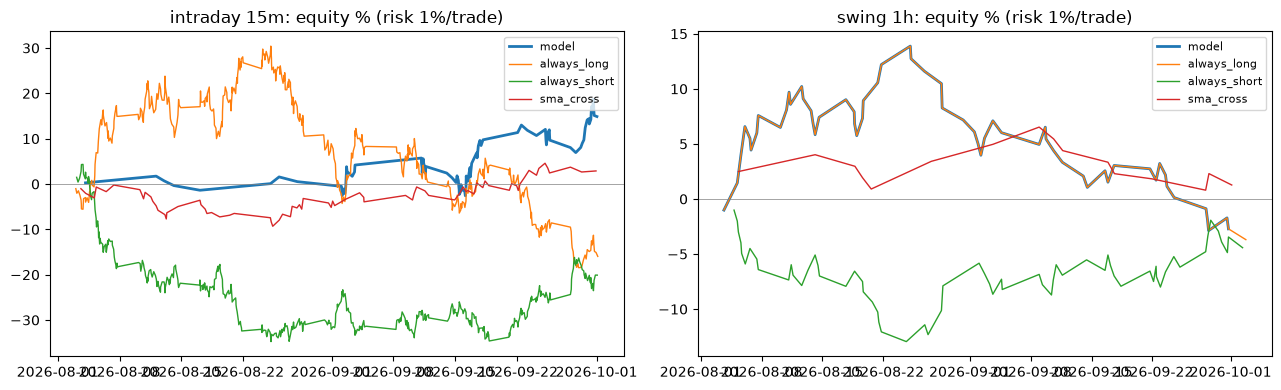

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, res) in zip(axes, (("intraday 15m", res_i), ("swing 1h", res_s))):
    for k, tr in res.items():
        if len(tr):
            ax.plot(pd.to_datetime(tr["exit"]), 100 * (tr["equity"] - 1), label=k, lw=2 if k == "model" else 1)
    ax.axhline(0, color="grey", lw=0.5); ax.set_title(f"{name}: equity % (risk 1%/trade)"); ax.legend(fontsize=8)
plt.tight_layout()

## สรุป

ดูตัวเลขในเซลล์ด้านบน — ประเด็นที่ต้องอ่านคู่กัน:
- **intraday** เป็นโมเดลเดียวที่ชนะ baseline บน holdout จริง แต่เป็น **long-only** (ไม่มีสัญญาณ short เลย) และเทรดกระจุกในเดือนกันยายน; CI 90% ของ expectancy ยังคร่อม 0
- **swing** ส่งสัญญาณ long เกือบทุกแท่ง = always long ในทางปฏิบัติ ไม่มี edge
- เทียบ LLM harness ช่วงเดียวกัน (intraday, ส.ค. 3–ต.ค. 4): 26 trades, win 23.1%, PF 0.41, −0.59R
- ข้อจำกัด: ราคาเป็น futures ไม่ใช่ spot ของ broker (ส่วนต่างคงที่ไม่กระทบ feature), simulator ไม่มี reversal/lot rounding